# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 2 (Semana 14). PCA y evaluación de mejoras al modelo

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Predicción de entregas tardías en Olist (ID 26)

Objetivo: comprobar si reducir las variables numéricas con PCA y cambiar la regularización (C) mejora la
detección de pedidos tardíos, y si las particiones de entrenamiento y validación se parecen (prueba KS).

Las secciones 1 y 2 (carga, preparación, muestra y preprocesamiento) son las mismas de la semana 12.
Las secciones 3 a 8 las desarrollo yo.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [3]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

C:\Users\cifue\AppData\Local\Temp\ipykernel_14468\3678014271.py:16: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data['dia_semana_compra'] = compra.dt.dayofweek


Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [6]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [7]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 26
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 26 | Semilla: 1026
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 78a4ad412176


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [8]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


## 3. PCA: reducir las variables numéricas (Actividad 1)

Idea: PCA resume variables que se parecen entre sí en pocas variables nuevas (componentes).
Se ajusta **solo con entrenamiento**, después de imputar y estandarizar. Las 4 categóricas no entran en el PCA.

In [9]:
import sys
import sklearn
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.decomposition import PCA

# Carpeta raíz del repositorio (sube hasta encontrar .git) y carpeta de reportes de la semana 14.
RAIZ = Path.cwd()
while RAIZ != RAIZ.parent and not (RAIZ / '.git').exists():
    RAIZ = RAIZ.parent
if not (RAIZ / '.git').exists():  # sin repositorio (por ejemplo, Colab): carpeta actual
    RAIZ = Path.cwd()
carpeta_reportes = RAIZ / 'reports' / 'S14'
carpeta_reportes.mkdir(parents=True, exist_ok=True)

Variables numéricas iniciales: 24
Componentes para explicar al menos el 90 %: 15
Varianza acumulada con esos componentes: 0.9039


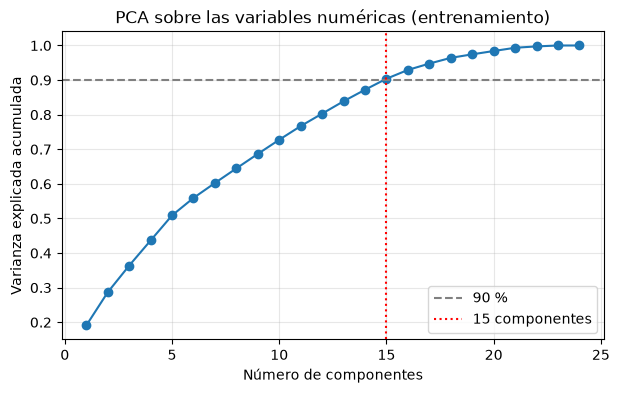

In [10]:
# Actividad 1. PCA sobre las variables numéricas (solo con entrenamiento).

# 1) Imputar con la mediana y estandarizar. Se ajusta con entrenamiento.
prep_numericas = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
X_train_num = prep_numericas.fit_transform(X_train[columnas_numericas])

# 2) PCA con todos los componentes para ver cuánta varianza aporta cada uno.
pca_completo = PCA(random_state=semilla)
pca_completo.fit(X_train_num)
varianza_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)

# 3) Menor número de componentes que explica al menos el 90 % de la varianza.
n_numericas = len(columnas_numericas)
n_componentes = int(np.argmax(varianza_acumulada >= 0.90) + 1)
print('Variables numéricas iniciales:', n_numericas)
print('Componentes para explicar al menos el 90 %:', n_componentes)
print('Varianza acumulada con esos componentes:', round(float(varianza_acumulada[n_componentes - 1]), 4))

# 4) Curva de varianza explicada acumulada (también se guarda en reports/S14/).
plt.figure(figsize=(7, 4))
plt.plot(range(1, n_numericas + 1), varianza_acumulada, marker='o')
plt.axhline(0.90, color='gray', linestyle='--', label='90 %')
plt.axvline(n_componentes, color='red', linestyle=':', label=f'{n_componentes} componentes')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('PCA sobre las variables numéricas (entrenamiento)')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(carpeta_reportes / f'S14_varianza_acumulada_ID_{identificador}.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Cuatro experimentos con la misma muestra y partición (Actividad 2)

| Experimento | Transformación | C |
|---|---|---|
| A. Referencia | Numéricas sin PCA | 1,0 |
| B. Reducción | PCA con 90 % de varianza | 1,0 |
| C. Mayor penalización | PCA con 90 % de varianza | 0,1 |
| D. Menor penalización | PCA con 90 % de varianza | 10,0 |

Los cuatro usan `class_weight='balanced'`, umbral 0,50 y evalúan en **validación** (la prueba no se toca).

In [11]:
# Actividad 2. Cuatro experimentos con la misma muestra, la misma partición y el umbral 0,50.
def armar_preprocesamiento(usar_pca):
    pasos_numericas = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        pasos_numericas.append(PCA(n_components=0.90, random_state=semilla))
    categoricas = make_pipeline(SimpleImputer(strategy='most_frequent'),
                                OneHotEncoder(handle_unknown='ignore'))
    return ColumnTransformer([
        ('numericas', make_pipeline(*pasos_numericas), columnas_numericas),
        ('categoricas', categoricas, columnas_categoricas),
    ])


experimentos = {
    'A. Referencia (sin PCA, C=1)': (False, 1.0),
    'B. PCA 90 % (C=1)': (True, 1.0),
    'C. PCA 90 % (C=0,1)': (True, 0.1),
    'D. PCA 90 % (C=10)': (True, 10.0),
}

filas, predicciones = [], {}
for nombre, (usar_pca, C) in experimentos.items():
    modelo_exp = make_pipeline(
        armar_preprocesamiento(usar_pca),
        LogisticRegression(C=C, class_weight='balanced', max_iter=1000, random_state=semilla)
    )
    modelo_exp.fit(X_train, y_train)
    proba_exp = modelo_exp.predict_proba(X_valid)[:, 1]
    pred_exp = (proba_exp >= 0.50).astype(int)
    predicciones[nombre] = pred_exp
    filas.append({
        'experimento': nombre,
        'accuracy': accuracy_score(y_valid, pred_exp),
        'precision': precision_score(y_valid, pred_exp, zero_division=0),
        'recall': recall_score(y_valid, pred_exp),
        'f1': f1_score(y_valid, pred_exp, zero_division=0),
        'ap': average_precision_score(y_valid, proba_exp),
    })
    if usar_pca:
        n_usados = modelo_exp[0].named_transformers_['numericas'][-1].n_components_
        print(nombre, '-> componentes usados por el modelo:', n_usados,
              '(coincide con la actividad 1)' if n_usados == n_componentes else '(OJO: distinto de la actividad 1)')

resultados_modelos = pd.DataFrame(filas).set_index('experimento')
print(resultados_modelos.round(3).to_string())

B. PCA 90 % (C=1) -> componentes usados por el modelo: 15 (coincide con la actividad 1)


C. PCA 90 % (C=0,1) -> componentes usados por el modelo: 15 (coincide con la actividad 1)


D. PCA 90 % (C=10) -> componentes usados por el modelo: 15 (coincide con la actividad 1)
                              accuracy  precision  recall     f1     ap
experimento                                                            
A. Referencia (sin PCA, C=1)     0.661      0.122   0.645  0.205  0.145
B. PCA 90 % (C=1)                0.646      0.112   0.611  0.189  0.127
C. PCA 90 % (C=0,1)              0.645      0.112   0.614  0.190  0.130
D. PCA 90 % (C=10)               0.646      0.112   0.611  0.189  0.126


## 5. Costo de los errores (Actividad 3)

Supuesto didáctico: R$ 8 por falso positivo y R$ 35 por falso negativo (no son costos reales de Olist).

In [12]:
# Actividad 3. Falsos positivos, falsos negativos y costo didáctico (R$ 8 por FP y R$ 35 por FN).
COSTO_FP, COSTO_FN = 8, 35

conteos = []
for nombre, pred_exp in predicciones.items():
    tn, fp, fn, tp = confusion_matrix(y_valid, pred_exp).ravel()
    conteos.append({'experimento': nombre, 'fp': int(fp), 'fn': int(fn),
                    'costo': COSTO_FP * int(fp) + COSTO_FN * int(fn)})
conteos = pd.DataFrame(conteos).set_index('experimento')
resultados_modelos = resultados_modelos.join(conteos)

costo_siempre_a_tiempo = COSTO_FN * int(y_valid.sum())
print(resultados_modelos.round(3).to_string())
print('\nCosto de no hacer nada (decir siempre "a tiempo"): R$', costo_siempre_a_tiempo)
print('Menor costo entre los 4 modelos:', resultados_modelos['costo'].idxmin(),
      '| R$', int(resultados_modelos['costo'].min()))

                              accuracy  precision  recall     f1     ap    fp   fn  costo
experimento                                                                              
A. Referencia (sin PCA, C=1)     0.661      0.122   0.645  0.205  0.145  1654  126  17642
B. PCA 90 % (C=1)                0.646      0.112   0.611  0.189  0.127  1719  138  18582
C. PCA 90 % (C=0,1)              0.645      0.112   0.614  0.190  0.130  1727  137  18611
D. PCA 90 % (C=10)               0.646      0.112   0.611  0.189  0.126  1721  138  18598

Costo de no hacer nada (decir siempre "a tiempo"): R$ 12425
Menor costo entre los 4 modelos: A. Referencia (sin PCA, C=1) | R$ 17642


## 6. Prueba de Kolmogorov-Smirnov sobre `valor_flete` (Actividad 4)

Compara la distribución de `valor_flete` entre entrenamiento y validación.

- H0: los valores de `valor_flete` se comportan igual en entrenamiento y en validación.
- H1: los valores de `valor_flete` se comportan distinto en entrenamiento y en validación.
- Nivel de significancia: 5 %

In [13]:
# Actividad 4. Prueba KS de dos muestras sobre valor_flete (entrenamiento vs validación).
resultado_ks = ks_2samp(train['valor_flete'].dropna(), valid['valor_flete'].dropna())
estadistico_D = float(resultado_ks.statistic)
valor_p = float(resultado_ks.pvalue)
alfa = 0.05

print('Estadístico D:', round(estadistico_D, 4))
print('Valor p:', round(valor_p, 4))
print('Decisión al 5 %:', 'se rechaza H0' if valor_p < alfa else 'no se rechaza H0')

Estadístico D: 0.0144
Valor p: 0.3242
Decisión al 5 %: no se rechaza H0


## 7. Interpretación

1. PCA: ¿cuántas variables numéricas había, cuántos componentes se conservaron y qué información podría perderse al comprimirlas?

Respuesta: En mi muestra hay 24 variables numéricas. Con el PCA me quedé con 15 componentes, que guardan el 90,4 % de la información (la varianza). Es decir, pasé de 24 columnas a 15, porque varias variables se parecen y dicen casi lo mismo. Al reducir se pierde el 9,6 % restante, y ahí puede haber datos pequeños pero útiles para saber si un pedido llegará tarde. Además, cada componente junta varias variables, así que ya no se sabe qué significa cada uno y es más difícil explicar el modelo.

2. Compara el modelo sin PCA con los modelos con PCA (Accuracy, Precision, Recall, F1 y AP). ¿Mejoró algo?

Respuesta: El modelo sin PCA (A) tuvo Accuracy 0,661, Precision 0,122, Recall 0,645, F1 0,205 y AP 0,145. Los tres modelos con PCA (B, C y D) tuvieron Accuracy entre 0,645 y 0,646, Recall entre 0,611 y 0,614, F1 entre 0,189 y 0,190 y AP entre 0,126 y 0,130. Ninguno con PCA fue mejor que A en Recall, F1 ni AP, y tampoco bajó el costo. Entonces, reducir las variables no ayudó a encontrar más pedidos tardíos: se perdió un poco de información útil. El valor de C controla qué tanto se frena al modelo para que no se pegue demasiado a los datos de entrenamiento. Cambiar C (0,1, 1 y 10) casi no cambió los resultados: el F1 de B, C y D se diferencia en menos de 0,000. Una posible razón es que con pocos componentes el modelo ya es simple, y por eso frenarlo más o menos cambia poco.

3. ¿Qué modelo eliges (más aciertos, más tardías detectadas o menor costo)? Justifica con tus cifras.

Respuesta: Elijo el modelo A (sin PCA, C=1), porque es el que tiene el menor costo en validación: R$ 17.642, con 1.654 falsos positivos y 126 falsos negativos. Me fijo en el costo y no en el Accuracy porque dejar pasar un pedido tardío cuesta R$ 35 y una alerta de más cuesta solo R$ 8. Además, es el mejor de los cuatro en Recall, F1 y AP. También es el más simple, porque no usa PCA. Aun así, su costo es mayor que el de no hacer nada (R$ 12.425), porque con el umbral de 0,50 el modelo da muchas alertas que no se cumplen. El siguiente paso sería subir el umbral, como probé en la semana 12.

4. KS: estadístico D, valor p, decisión al 5 % y una limitación de la prueba.

Respuesta: El estadístico D fue 0,0144 y el valor p fue 0,3242. Como el valor p es mayor que 0,05, no rechazo H0: no hay pruebas de que el valor del flete sea distinto en entrenamiento y validación, así que los dos grupos se parecen en esta variable. Una limitación es que la prueba mira una sola variable, así que no asegura que las demás también se parezcan. Además, un valor p alto no demuestra que sean iguales, solo que no se encontró una diferencia.

## 8. Registro de resultados

In [14]:
# Registro de resultados: reporte JSON y resumen en reports/S14/.
ruta = carpeta_reportes / f'S14_resultados_ID_{identificador}.json'

reporte = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.now('UTC').isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'huella_muestra': huella_muestra,
    'umbral_clasificacion': 0.50,
    'costos_didacticos_brl': {'falso_positivo': COSTO_FP, 'falso_negativo': COSTO_FN},
    'pca': {'n_numericas': n_numericas, 'umbral_varianza': 0.90, 'n_componentes': n_componentes,
            'varianza_acumulada': float(varianza_acumulada[n_componentes - 1])},
    'experimentos': json.loads(resultados_modelos.reset_index().to_json(orient='records')),
    'ks_valor_flete': {'D': estadistico_D, 'p_valor': valor_p, 'alfa': alfa,
                       'decision': 'rechaza H0' if valor_p < alfa else 'no rechaza H0'},
    'modelo_elegido': resultados_modelos['costo'].idxmin(),  # menor costo en validación
}
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# Resumen del análisis: solo se crea si no existe, para no borrar lo que yo escriba después.
ruta_resumen = carpeta_reportes / f'S14_resumen_ID_{identificador}.md'
if not ruta_resumen.exists():
    def miles(n):
        return f'{int(n):,}'.replace(',', '.')

    def dec(x, n=3):
        return f'{float(x):.{n}f}'.replace('.', ',')

    lineas = [
        f'# S14. Resumen del análisis (ID {identificador})', '',
        '## Datos de partida',
        f'- Muestra: {miles(len(muestra))} pedidos ({miles(len(train))} de entrenamiento, '
        f'{miles(len(valid))} de validación y {miles(len(test))} de prueba sin usar).',
        '- Umbral de clasificación: 0,50. Costos didácticos: R$ 8 por falso positivo y R$ 35 por falso negativo.', '',
        '## PCA',
        f'- Variables numéricas iniciales: {n_numericas}. Componentes que explican al menos el 90 %: '
        f'{n_componentes} (varianza acumulada {dec(varianza_acumulada[n_componentes - 1])}).',
        f'- Figura: `S14_varianza_acumulada_ID_{identificador}.png`', '',
        '## Resultados en validación',
        '| Experimento | Accuracy | Precision | Recall | F1 | AP | FP | FN | Costo (R$) |',
        '|---|---|---|---|---|---|---|---|---|',
    ]
    for nombre, f in resultados_modelos.iterrows():
        lineas.append(f"| {nombre} | {dec(f['accuracy'])} | {dec(f['precision'])} | {dec(f['recall'])} | "
                      f"{dec(f['f1'])} | {dec(f['ap'])} | {miles(f['fp'])} | {miles(f['fn'])} | {miles(f['costo'])} |")
    lineas += [
        '', '## Prueba KS sobre `valor_flete` (entrenamiento vs validación)',
        f'- D = {dec(estadistico_D, 4)}; valor p = {dec(valor_p, 4)}; alfa = 0,05.',
        '- Hipótesis y decisión: (pendiente, la escribo yo)', '',
        '## Interpretación (pendiente, la escribo yo)',
        '- Modelo elegido y justificación:',
        '- Utilidad de PCA para este problema:',
        '- Limitación de la prueba KS:', '',
    ]
    ruta_resumen.write_text('\n'.join(lineas), encoding='utf-8')
    print('Resumen creado:', ruta_resumen)
else:
    print('El resumen ya existe y no se tocó:', ruta_resumen)

Reporte: C:\Users\cifue\ml_challenge_da2026_26\reports\S14\S14_resultados_ID_26.json
Resumen creado: C:\Users\cifue\ml_challenge_da2026_26\reports\S14\S14_resumen_ID_26.md
